<!-- reader-content -->

# Resonator depletion with CLEAR

<!-- notebook-download -->

When a readout pulse stops, photons remain in the resonator and decay. A
[CLEAR pulse](https://arxiv.org/abs/1503.01456) adds loading and depletion
segments that build up and remove the coherent field faster. How much faster
does it empty a readout resonator behind a Purcell filter? Frequencies are in
GHz and times in ns.

## Define the filtered readout

Use the filtered circuit from the [Purcell study](purcell-filter.md): a 5 GHz
transmon, a 7 GHz readout resonator, and a 7.02 GHz Purcell filter, with the
line coupled to the filter. Both pulses use the same 7.004945 GHz carrier, a
weak-drive estimate of the conditional response midpoint that includes the
lossy filter, and that carrier is also the IQ reference.

In [1]:
import numpy as np
from quchip import Capacitive, Chip, DuffingTransmon, PortNetwork, QuantumSequence, Resonator, RWA, Square

clear_carrier = 7.004945346
clear_q = DuffingTransmon(freq=5.0, anharmonicity=-0.2, levels=3, T1=60_000, label="q")
clear_r = Resonator(freq=7.0, levels=4, internal_quality_factor=200_000, label="r")
clear_f = Resonator(freq=7.02, levels=2, internal_quality_factor=100_000, label="f")
clear_r.reference_freq = clear_carrier

clear_network = PortNetwork(label="feedline")
filter_rate = 2 * np.pi * 0.230
chip_port = clear_network.expose("feedline", at=clear_network.port("feed", target=clear_f, rate=filter_rate))

clear_chip = Chip(
    [clear_q, clear_r, clear_f],
    [Capacitive(clear_q, clear_r, g=0.105, label="qr"),
     Capacitive(clear_r, clear_f, g=0.007696696, label="rf")],
    port_network=clear_network, frame=clear_carrier, approximation=RWA(),
)

## Check the carrier

Check the carrier against the weak-probe reflection at the filter port.
`VNA.sweep(..., when=...)` holds the qubit in a dressed reference state, and
each response has a dip at its readout resonance.

In [2]:
from quchip import VNA

probe_frequencies = np.linspace(7.003, 7.007, 4001)
reflection = VNA(clear_chip)
responses = [reflection.sweep(probe_frequencies, when={clear_q: level}) for level in (0, 1)]
dips = [probe_frequencies[np.argmin(np.abs(response.s11))] for response in responses]
closed = [float(clear_chip.freq(clear_r, when={clear_q: level})) for level in (0, 1)]
escape_rate = float(responses[1].diagnostics[0]["reference_escape_rate"])

print(f"Reflection dips: {dips[0]:.6f} GHz for |0⟩, {dips[1]:.6f} GHz for |1⟩")
print(f"Carrier minus dip midpoint: {1e6 * (clear_carrier - np.mean(dips)):.1f} kHz")
print(f"Closed-model midpoint minus dip midpoint: {1e3 * (np.mean(closed) - np.mean(dips)):.2f} MHz")
print(f"Excited-reference escape rate: {escape_rate:.3g} /ns")

Reflection dips: 7.005432 GHz for |0⟩, 7.004445 GHz for |1⟩
Carrier minus dip midpoint: 6.8 kHz
Closed-model midpoint minus dip midpoint: -3.18 MHz
Excited-reference escape rate: 1.73e-05 /ns


The carrier lies 6.8 kHz above the dip midpoint, under 1% of the 1 MHz
readout linewidth. `chip.freq()` diagonalizes the closed Hamiltonian, which
treats the filter as a lossless mode and so puts the readout midpoint
3.2 MHz below the dips. The filter's 230 MHz linewidth is much larger than
its 20 MHz detuning from the readout, so the driven response keeps little of
that pull. The excited reference escapes at 1/(57.9 µs), the filtered T1 of
the Purcell study. This total rate includes the intrinsic qubit decay and is slow
on the readout timescale.

## Design the two pulses

Both pulses start at 100 ns and use the same carrier and hold amplitude
(in √photons/ns). The square pulse stops at 900 ns, while CLEAR uses two
loading segments, a hold, and then two depletion segments that end at
1300 ns, where a negative amplitude is a π phase reversal. These five coefficients are a
weak-drive starting design for this circuit, so retune them if you change
the circuit or carrier.

In [3]:
hold_amplitude = 0.008
segment_amplitudes = np.array([2.318735, 0.378724, 1.0, -1.318735, 0.621276])
segment_edges = np.array([100, 300, 500, 900, 1100, 1300])

square_sequence = QuantumSequence(clear_chip)
_ = square_sequence.schedule(chip_port.input, envelope=Square(duration=800, amplitude=hold_amplitude),
                             freq=clear_carrier, start_time=100)

clear_sequence = QuantumSequence(clear_chip)
for start, duration, scale in zip(segment_edges[:-1], np.diff(segment_edges), segment_amplitudes):
    _ = clear_sequence.schedule(
        chip_port.input, envelope=Square(duration=duration, amplitude=hold_amplitude * abs(scale)),
        phase=np.pi if scale < 0 else 0, freq=clear_carrier, start_time=start,
    )

## Simulate both preparations

Prepare dressed |0,0,0⟩ and |1,0,0⟩ states of the resolved RWA model, and
run each pulse on both preparations, recording the occupations and the
readout field αᵣ = ⟨aᵣ⟩. The explicit time grid resolves the fast qubit–resonator
exchange. The `matrix_form` solver option requires
[QuTiP 5.3+](https://qutip.readthedocs.io/en/qutip-5.3.x/apidoc/solver.html).

In [4]:
clear_times = np.linspace(0, 1900, 9501)
clear_dressed = clear_chip.resolve().dress(overlap_threshold=0.0)
clear_preparations = [clear_dressed.eigenstates[clear_dressed.state_map[(level, 0, 0)]] for level in (0, 1)]

clear_batches = {}
for name, pulse_sequence in [("Square", square_sequence), ("CLEAR", clear_sequence)]:
    clear_batches[name] = pulse_sequence.simulate_batch(
        pulse_sequence.vary("initial_state", clear_preparations), tlist=clear_times,
        e_ops=clear_chip.e_ops(q="n", r=["n", "a"], f="n"),
        states="none", progress=False,
        options={"method": "vern9", "matrix_form": True, "rtol": 1e-7, "atol": 1e-10},
    )

clear_occupations = {name: np.stack([batch.expect("q"), batch.expect("r", index=0), batch.expect("f")]).real
                     for name, batch in clear_batches.items()}
clear_iq = {name: np.asarray(batch.expect("r", index=1)) for name, batch in clear_batches.items()}

## Compare passive decay with depletion

Plot each drive and the mean occupation of each mode for the ground-state
preparation.

<details>
<summary>Plot pulse shapes and mode occupations</summary>

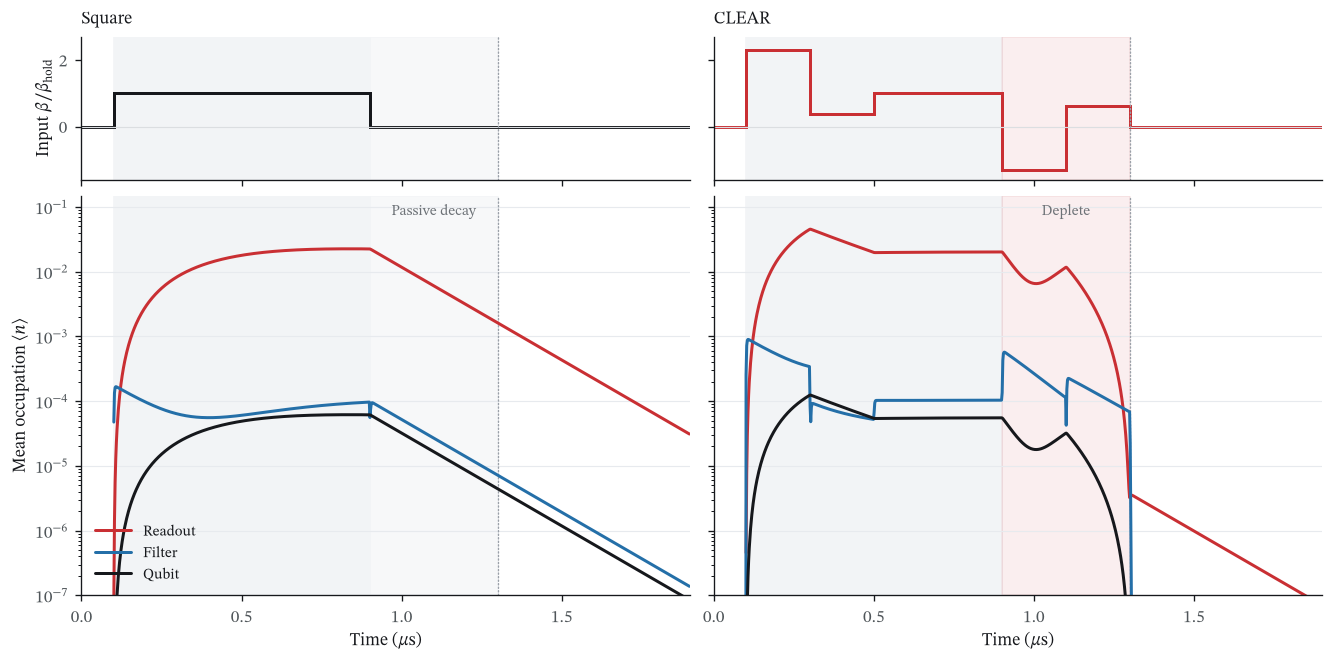

In [5]:
import shutil
from pathlib import Path

import matplotlib.pyplot as plt

# In a quchip checkout, use the documentation style and save the figures there.
docs = Path("../docs")
if docs.is_dir():
    plt.style.use(docs / "_static/quchip.mplstyle")
plt.rcParams["text.usetex"] = bool(shutil.which("latex"))

figure, axes = plt.subplots(2, 2, figsize=(11, 5.4), sharex=True, sharey='row',
                            height_ratios=(1, 2.8), layout='constrained')
plot_times = (clear_times[:-1:10] + clear_times[10::10]) / 2000
for column, name in enumerate(('Square', 'CLEAR')):
    pulse_axis, population_axis = axes[:, column]
    scales = np.array([1.0]) if name == 'Square' else segment_amplitudes
    edges = np.array([100, 900]) if name == 'Square' else segment_edges
    pulse_axis.stairs(np.r_[0, scales, 0], np.r_[0, edges, 1900] / 1000,
                       color='#16181C' if name == 'Square' else '#C92F33', lw=1.8)
    pulse_axis.set_title(name)
    pulse_axis.axhline(0, color="#DBDEE1", lw=.7)
    pulse_axis.set_ylim(-1.6, 2.7)
    pulse_axis.grid(False)
    for axis in (pulse_axis, population_axis):
        axis.axvspan(.1, .9, color='#F2F4F6', zorder=0)
        if name == 'CLEAR':
            axis.axvspan(.9, 1.3, color='#C92F33', alpha=0.08, zorder=0)
        else:
            axis.axvspan(.9, 1.3, color='#F2F4F6', alpha=0.6, zorder=0)
        axis.axvline(1.3, color='#9AA0A8', ls=':', lw=.8)
    # Trapezoidal means over 2 ns bins; state 0 is the ground preparation.
    values = clear_occupations[name][:, 0]
    averaged = (values[:, :-1].reshape(3, -1, 10).sum(axis=-1)
                - .5 * values[:, :-1:10] + .5 * values[:, 10::10]) / 10
    for index, label, color in ((1, 'Readout', '#C92F33'), (2, 'Filter', '#246FA8'), (0, 'Qubit', '#16181C')):
        population_axis.semilogy(plot_times, np.where(averaged[index] > 0, averaged[index], np.nan),
                                 color=color, lw=1.8, label=label)
    population_axis.text(1.1, .075, 'Deplete' if name == 'CLEAR' else 'Passive decay',
                         ha='center', color='#6D7277', fontsize=9)
    population_axis.set(xlabel=r'Time ($\mu$s)', xlim=(0, 1.9), ylim=(1e-7, .15), xticks=[0, .5, 1, 1.5])

axes[0, 0].set_ylabel(r'Input $\beta/\beta_{\mathrm{hold}}$')
axes[1, 0].set_ylabel(r'Mean occupation $\langle n\rangle$')
axes[1, 0].legend(fontsize=9, loc='lower left')

if docs.is_dir():
    figure.savefig(docs / "images/clear_populations.svg")
plt.show()

</details>

```{figure} ../images/clear_populations.svg
:class: wide-figure
:alt: Square and CLEAR input pulses above the readout, filter, and qubit occupations, showing passive decay versus active depletion.

The qubit starts in its ground state, and occupations are averaged over
2 ns bins. CLEAR uses extra drive during loading and depletion. Its final
segments remove readout photons much faster than waiting over the same
900–1300 ns interval. The small qubit occupation includes hybridization with
the resonator.
[PDF](../images/clear_populations.pdf)
```

The IQ paths show how the depletion segments move the coherent readout field
back toward zero for both qubit preparations.

<details>
<summary>Plot the readout IQ trajectories</summary>

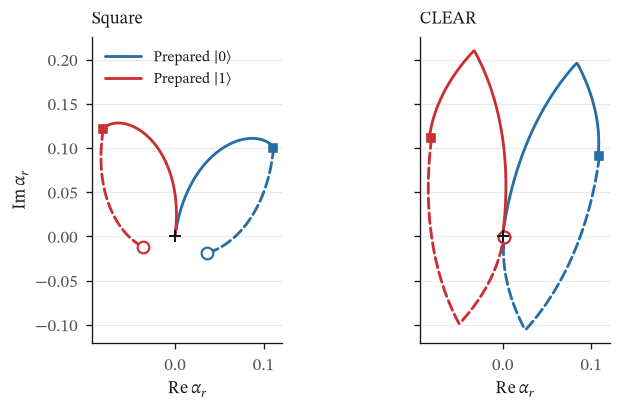

In [6]:
figure, axes = plt.subplots(1, 2, figsize=(5.6, 3.3), sharex=True, sharey=True, layout='constrained')
readout_end = np.searchsorted(clear_times, 900)
reset_end = np.searchsorted(clear_times, 1300)
for axis, name in zip(axes, ('Square', 'CLEAR')):
    for level, color in ((0, '#246FA8'), (1, '#C92F33')):
        iq = clear_iq[name][level]
        axis.plot(iq[:readout_end+1].real, iq[:readout_end+1].imag, color=color, lw=1.7,
                  label=fr'Prepared $|{level}\rangle$')
        axis.plot(iq[readout_end:reset_end+1].real, iq[readout_end:reset_end+1].imag,
                  color=color, ls='--', lw=1.7)
        axis.plot(iq[readout_end].real, iq[readout_end].imag, 's', color=color, ms=5)
        axis.plot(iq[reset_end].real, iq[reset_end].imag, 'o', mec=color, mfc='white', mew=1.3, ms=7)
    axis.plot(0, 0, '+', color='#16181C', ms=7, mew=1.2)
    axis.set_title(name)
    axis.set_xlabel(r'$\mathrm{Re}\,\alpha_r$')
    axis.set_aspect('equal', adjustable='box')

axes[0].set_ylabel(r'$\mathrm{Im}\,\alpha_r$')

axes[0].legend(fontsize=9, loc='upper left')

if docs.is_dir():
    figure.savefig(docs / "images/clear_iq.svg")
plt.show()

</details>

```{figure} ../images/clear_iq.svg
:class: wide-figure
:alt: Readout IQ paths for both qubit preparations under square and CLEAR pulses, with the end of readout and end of depletion marked.

Squares mark 900 ns, and open circles mark 1300 ns. Dashed paths cover that
interval. CLEAR brings both mean fields close to the origin. These paths show
how the coherent field cancels. Their |⟨aᵣ⟩|² is not the total photon
occupation.
[PDF](../images/clear_iq.pdf)
```

<details>
<summary>Check depletion at the same elapsed time</summary>

In [7]:
reset_index = np.searchsorted(clear_times, 1300)
for values in clear_occupations.values():
    assert np.all(np.isfinite(values))
assert clear_occupations["CLEAR"][1, 0, reset_index] < clear_occupations["Square"][1, 0, reset_index] / 100
for level in (0, 1):
    assert clear_dressed.assignment_overlaps[(level, 0, 0)] > 0.99
    assert abs(clear_iq["CLEAR"][level, reset_index])**2 < abs(clear_iq["Square"][level, reset_index])**2 / 100

</details>

The excited preparation also keeps its dressed qubit excitation, so zero
mean field does not mean a vacuum state. For the signal at the instrument
ports, continue with [readout and fridge wiring](../guides/steady-state-and-vna.md).